<a href="https://colab.research.google.com/github/lgonperez3-glitch/MLSM-labs/blob/main/Lab2/lab2_task2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2 — Task 2: clasificación de géneros musicales con una CNN

**Versión mejorada y preparada para Google Colab.** Entrena una CNN desde cero sobre imágenes de espectrogramas y compara 16 configuraciones.

Antes de entrenar, selecciona una GPU en **Entorno de ejecución → Cambiar tipo de entorno de ejecución**. El dataset debe estar en Google Drive dentro de `Data/images_original`.

**Importante:** los resultados anteriores no se reutilizan, porque los cambios en el aumento de datos y la medición de accuracy hacen que las ejecuciones anteriores no sean directamente comparables. Esta versión guarda sus resultados en una carpeta nueva.

In [4]:
# Configuración de Google Colab y localización del dataset
import pandas as pd
from IPython.display import display
from google.colab import drive
from pathlib import Path
import os

drive.mount('/content/drive')

Mounted at /content/drive


## 1. Importaciones y configuración general

Importamos TensorFlow para construir y entrenar la CNN, scikit-learn para dividir los datos y calcular métricas, y Matplotlib/Pandas para mostrar resultados.

Fijar las semillas aleatorias hace que las particiones y la inicialización sean más reproducibles, aunque no garantiza resultados idénticos en todos los tipos de GPU.

In [5]:
# Si falta alguna librería, ejecuta esta línea en una celda aparte:
# %pip install tensorflow scikit-learn matplotlib pandas

import os
import random
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Semillas aleatorias para facilitar la reproducibilidad.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = "/content/drive/MyDrive/MLSM/Data/images_original"
BATCH_SIZE = 32
MAX_EPOCHS = 50

# Mostrar la configuración general como tabla, sin prints sueltos.
display(pd.DataFrame([
    {"Elemento": "TensorFlow", "Valor": tf.__version__},
    {"Elemento": "Épocas por configuración", "Valor": MAX_EPOCHS},
    {"Elemento": "Tamaño de lote", "Valor": BATCH_SIZE},
    {"Elemento": "Semilla aleatoria", "Valor": SEED},
    {"Elemento": "Carpeta de imágenes", "Valor": DATA_DIR},
]))


,Elemento,Valor
0,TensorFlow,2.21.0
1,Épocas por configuración,50
2,Tamaño de lote,32
3,Semilla aleatoria,42
4,Carpeta de imágenes,/content/drive/MyDrive/MLSM/Data/images_original


## 2. Cargar las imágenes y dividir los datos

Cada subcarpeta de `images_original` debe representar un género musical. Reservamos el 20 % para test y dividimos el 80 % restante en entrenamiento y validación.

La partición final es aproximadamente **64 % entrenamiento, 16 % validación y 20 % test**. La división estratificada conserva la proporción de géneros. El conjunto de test no se usa para elegir modelos ni hiperparámetros.

In [6]:
# Comprobar que la ruta existe antes de leer los archivos.
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"No encuentro la carpeta '{DATA_DIR}'. Cambia DATA_DIR para indicar la ruta correcta."
    )

# Cada subcarpeta representa un género musical.
class_names = sorted(
    folder for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
)

valid_extensions = (".png", ".jpg", ".jpeg", ".bmp")
paths = []
labels = []

for label, genre in enumerate(class_names):
    genre_folder = os.path.join(DATA_DIR, genre)
    for filename in sorted(os.listdir(genre_folder)):
        if filename.lower().endswith(valid_extensions):
            paths.append(os.path.join(genre_folder, filename))
            labels.append(label)

paths = np.asarray(paths)
labels = np.asarray(labels)

if len(paths) == 0:
    raise ValueError("No se encontraron imágenes. Comprueba DATA_DIR.")
if len(class_names) < 2:
    raise ValueError("Se necesitan al menos dos carpetas de géneros.")

# División estratificada: 64 % train, 16 % validación y 20 % test.
dev_paths, test_paths, dev_labels, test_labels = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels
)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    dev_paths, dev_labels, test_size=0.20, random_state=SEED, stratify=dev_labels
)

# Tabla del tamaño de cada partición.
split_df = pd.DataFrame([
    {"Conjunto": "Entrenamiento", "Imágenes": len(train_paths), "Porcentaje": 100 * len(train_paths) / len(paths)},
    {"Conjunto": "Validación", "Imágenes": len(val_paths), "Porcentaje": 100 * len(val_paths) / len(paths)},
    {"Conjunto": "Test", "Imágenes": len(test_paths), "Porcentaje": 100 * len(test_paths) / len(paths)},
    {"Conjunto": "TOTAL", "Imágenes": len(paths), "Porcentaje": 100.0},
])
display(split_df.round(2))

# Tabla con la distribución de géneros en cada partición.
distribution_rows = []
for genre_id, genre in enumerate(class_names):
    distribution_rows.append({
        "Género": genre,
        "Entrenamiento": int(np.sum(train_labels == genre_id)),
        "Validación": int(np.sum(val_labels == genre_id)),
        "Test": int(np.sum(test_labels == genre_id)),
        "Total": int(np.sum(labels == genre_id)),
    })
display(pd.DataFrame(distribution_rows))


,Conjunto,Imágenes,Porcentaje
0,Entrenamiento,639,63.96
1,Validación,160,16.02
2,Test,200,20.02
3,TOTAL,999,100.00


,Género,Entrenamiento,Validación,Test,Total
0,blues,64,16,20,100
1,classical,64,16,20,100
2,country,64,16,20,100
3,disco,64,16,20,100
4,hiphop,64,16,20,100
5,jazz,63,16,20,99
6,metal,64,16,20,100
7,pop,64,16,20,100
8,reggae,64,16,20,100
9,rock,64,16,20,100


## 3. Preparar los datasets de imágenes

Las imágenes se decodifican como RGB y se redimensionan al tamaño que necesite cada experimento. Las etiquetas son enteros, por lo que usamos `sparse_categorical_crossentropy`.

Solo se baraja el conjunto de entrenamiento. La carga en paralelo y `prefetch` permiten preparar datos mientras la GPU procesa el lote actual.

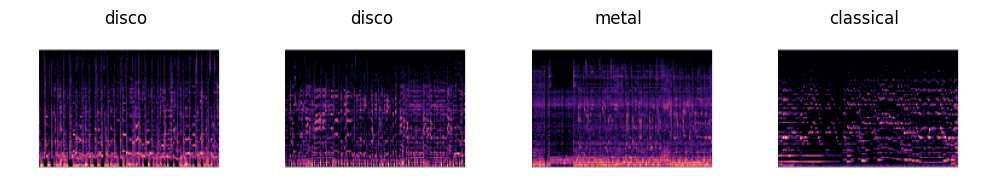

In [7]:
# Leer una imagen, convertirla a RGB y cambiar su resolución.
def load_image(path, label, size):
    image_bytes = tf.io.read_file(path)
    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, size)
    return image, label


# Crear un dataset por lotes para entrenar o evaluar el modelo.
def make_dataset(file_paths, file_labels, size, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))

    # Barajar solo entrenamiento; la semilla mantiene el proceso reproducible.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(file_paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Cargar y redimensionar imágenes en paralelo.
    dataset = dataset.map(
        lambda path, label: load_image(path, label, size),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Agrupar imágenes y preparar el siguiente lote mientras se entrena.
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# Mostrar algunos ejemplos para comprobar que las imágenes y etiquetas se leen bien.
preview_ds = make_dataset(
    train_paths, train_labels, size=(128, 192), training=False
)

for images, labels_batch in preview_ds.take(1):
    plt.figure(figsize=(10, 3))
    for i in range(min(4, len(images))):
        plt.subplot(1, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels_batch[i].numpy())])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## 4. Configuraciones experimentales

Se mantiene la búsqueda de **6 arquitecturas + 10 factores** del Task 1 y sus valores numéricos (dropout, augmentation, learning rate, kernel y resolución). La diferencia estructural es que VGG16 tiene filtros fijos preentrenados: las seis configuraciones varían el número de bloques VGG16 utilizados. Las dos configuraciones con el mismo número de bloques, aunque tienen nombres diferentes heredados de Task 1, son arquitectónicamente idénticas y constituyen repeticiones. Los kernels configurables se aplican a una convolución adicional, nunca a los filtros preentrenados. Por ello no son experimentos arquitectónicos idénticos a Task 1.

Se mantiene el máximo de 50 épocas, AdamW + CosineDecay, EarlyStopping (patience=10, min_delta=0.001), guardado de resultados y selección mediante validación.

In [8]:
# Configuración base: cada experimento cambia solo el factor que indica su nombre.
# filters: número de filtros por bloque convolucional; más filtros aumentan la capacidad y el coste.
# kernel: tamaño de las ventanas convolucionales que detectan patrones locales.
# dropout: proporción de activaciones que se desactivan durante el entrenamiento para regularizar.
# augment: si se aplican transformaciones aleatorias a las imágenes durante el entrenamiento.
# lr: learning rate inicial de AdamW, es decir, el tamaño de los pasos al actualizar los pesos.
# size: (alto, ancho) de entrada; aumentar la resolución conserva detalle a cambio de cómputo.
BASE0 = dict(filters=(32, 64, 128), kernel=(3, 3), dropout=0.3,
             augment=True, lr=1e-3, size=(128, 192), vgg_blocks=3)

# Los 6 experimentos iniciales conservan los nombres y filtros de Task 1.
# En VGG16 los filtros preentrenados NO se pueden cambiar sin perder sus pesos.
# Por tanto, filters documenta la configuración de Task 1 que se compara y
# vgg_blocks controla cuántos bloques preentrenados se utilizan.
DEPTH_EXPERIMENTS = {
    "2conv_16-32": dict(filters=(16, 32), vgg_blocks=2),
    "3conv_16-32-64": dict(filters=(16, 32, 64), vgg_blocks=3),
    "3conv_32-64-128": dict(filters=(32, 64, 128), vgg_blocks=3),
    "4conv_16-32-64-128": dict(filters=(16, 32, 64, 128), vgg_blocks=4),
    "4conv_32-64-128-256": dict(filters=(32, 64, 128, 256), vgg_blocks=4),
    "5conv_32-64-128-256-256": dict(filters=(32, 64, 128, 256, 256), vgg_blocks=5),
}

# Mismos 10 cambios numéricos del Task 1. Los cambios de kernel afectan
# únicamente a una convolución NUEVA tras el extractor congelado: los kernels
# originales de VGG16 siguen siendo de 3x3.
FACTOR_EXPERIMENTS = {
    "dropout_0.0": dict(dropout=0.0),
    "dropout_0.5": dict(dropout=0.5),
    "no_augment": dict(augment=False),
    "lr_3e-4": dict(lr=3e-4),
    "lr_3e-3": dict(lr=3e-3),
    "kernel_5x5": dict(kernel=(5, 5)),
    "kernel_7x3_freq": dict(kernel=(7, 3)),
    "kernel_3x7_time": dict(kernel=(3, 7)),
    "size_64x96": dict(size=(64, 96)),
    "size_192x288": dict(size=(192, 288)),
}
assert len(DEPTH_EXPERIMENTS) == 6 and len(FACTOR_EXPERIMENTS) == 10

def merge_config(base, changes):
    return {**base, **changes}

display(pd.DataFrame([
    {"Configuración": name, "Filtros": str(changes["filters"])}
    for name, changes in DEPTH_EXPERIMENTS.items()
]))
print("La segunda etapa se definirá después de conocer la mejor profundidad.")

,Configuración,Filtros
0,2conv_16-32,"(16, 32)"
1,3conv_16-32-64,"(16, 32, 64)"
2,3conv_32-64-128,"(32, 64, 128)"
3,4conv_16-32-64-128,"(16, 32, 64, 128)"
4,4conv_32-64-128-256,"(32, 64, 128, 256)"
5,5conv_32-64-128-256-256,"(32, 64, 128, 256, 256)"


La segunda etapa se definirá después de conocer la mejor profundidad.


## 5. Construir VGG16

Se reutilizan los bloques preentrenados de ImageNet, congelados. La cabeza nueva contiene una convolución configurable de 128 filtros, GlobalAveragePooling2D, Dense(128), Dropout y softmax. VGG16 utiliza preprocess_input en lugar de Rescaling(1/255). Las transformaciones temporales, el optimizador y el criterio de selección coinciden con Task 1.

In [9]:
# Genera VGG16 preentrenada con una cabeza clasificadora comparable a Task 1.
def generate_model(num_classes, config):
    height, width = config["size"]
    inputs = tf.keras.Input(shape=(height, width, 3))
    x = inputs
    if config["augment"]:
        # Igual que Task 1: no desplazar el eje vertical de frecuencia.
        x = tf.keras.layers.RandomTranslation(0.0, 0.05)(x)
        x = tf.keras.layers.RandomZoom(0.0, 0.1)(x)
        x = tf.keras.layers.RandomContrast(0.1)(x)
    # VGG16 requiere preprocess_input, no Rescaling(1/255).
    x = tf.keras.applications.vgg16.preprocess_input(x)
    full_vgg = tf.keras.applications.VGG16(
        include_top=False, weights="imagenet", input_shape=(height, width, 3)
    )
    # Mantener exactamente los filtros preentrenados de VGG16.
    full_vgg.trainable = False
    blocks = config["vgg_blocks"]
    feature_extractor = tf.keras.Model(
        full_vgg.input, full_vgg.get_layer(f"block{blocks}_pool").output,
        name=f"vgg16_first_{blocks}_blocks"
    )
    x = feature_extractor(x, training=False)
    # Kernel configurable: capa adicional entrenable, no altera VGG16.
    x = tf.keras.layers.Conv2D(128, config["kernel"], padding="same",
                               activation="relu", name="additional_conv")(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    if config["dropout"] > 0:
        x = tf.keras.layers.Dropout(config["dropout"])(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs)
    steps_per_epoch = int(np.ceil(len(train_paths) / BATCH_SIZE))
    lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=config["lr"],
        decay_steps=max(1, steps_per_epoch * MAX_EPOCHS), alpha=0.0
    )
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=lr_schedule,
                                           weight_decay=1e-4),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"]
    )
    return model


class SaveBestWeights(tf.keras.callbacks.Callback):
    """Conserva los pesos de la época con mayor accuracy de validación."""
    def on_train_begin(self, logs=None):
        self.best_val_accuracy = -1.0
        self.best_weights = None
        self.best_epoch = 0

    def on_epoch_end(self, epoch, logs=None):
        val_accuracy = (logs or {}).get("val_accuracy")
        if val_accuracy is not None and val_accuracy > self.best_val_accuracy:
            self.best_val_accuracy = float(val_accuracy)
            self.best_weights = [weight.copy() for weight in self.model.get_weights()]
            self.best_epoch = epoch + 1

## 6. Entrenamiento y guardado de resultados

Cada configuración se entrena hasta **50 épocas**, con **EarlyStopping de paciencia 10** y mejora mínima de 0.001 en val_accuracy. Se guardan pesos, métricas e historiales en una carpeta independiente de Drive para reanudar tras una desconexión. El conjunto de test se reserva hasta seleccionar el ganador.

In [10]:
import json
from pathlib import Path

num_classes = len(class_names)

# Nueva carpeta: evita mezclar resultados obtenidos con una versión anterior del modelo.
RESULTS_DIR = Path("/content/drive/MyDrive/MLSM/Lab 2/task2_vgg16_results_v1")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = RESULTS_DIR / "task2_two_stage_experiments.csv"
WEIGHTS_DIR = RESULTS_DIR / "weights"
HISTORY_DIR = RESULTS_DIR / "histories"
WEIGHTS_DIR.mkdir(exist_ok=True)
HISTORY_DIR.mkdir(exist_ok=True)

# Los archivos se guardan por configuración para poder continuar si Colab se desconecta.
def weights_path(name):
    return WEIGHTS_DIR / f"{name}.weights.h5"

def history_path(name):
    return HISTORY_DIR / f"{name}.json"

def csv_rows():
    return pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()

def run_experiments(experiments, base, group):
    for index, (name, changes) in enumerate(experiments.items(), start=1):
        config = merge_config(base, changes)
        old = csv_rows()
        matching = old[old["name"] == name] if not old.empty else pd.DataFrame()

        # Comprueba que el resultado guardado corresponde a la misma configuración.
        # Como esta versión usa una carpeta nueva, no se reutilizan pesos de código antiguo.
        if not matching.empty:
            saved = matching.iloc[-1]
            same = (
                int(saved["vgg_blocks"]) == config["vgg_blocks"]

                and saved["filters"] == "-".join(map(str, config["filters"]))
                and saved["kernel"] == "x".join(map(str, config["kernel"]))
                and np.isclose(saved["dropout"], config["dropout"])
                and str(saved["augment"]).lower() == str(config["augment"]).lower()
                and np.isclose(saved["lr"], config["lr"])
                and int(saved["img_h"]) == config["size"][0]
                and int(saved["img_w"]) == config["size"][1]
            )
            if same and weights_path(name).exists() and history_path(name).exists():
                print(f"[{group} {index}/{len(experiments)}] Ya guardado: {name}")
                continue
            raise RuntimeError(
                f"Hay un resultado incompatible o incompleto para {name}. "
                f"Elimina la carpeta {RESULTS_DIR} si quieres empezar de cero."
            )

        print(f"[{group} {index}/{len(experiments)}] Entrenando {name}: {config}")
        tf.keras.backend.clear_session()
        gc.collect()

        # Reinicia las semillas para que cada experimento empiece de forma reproducible.
        tf.keras.utils.set_random_seed(SEED)

        # El dataset de entrenamiento se baraja; validación no se baraja ni se aumenta.
        train_ds = make_dataset(train_paths, train_labels, config["size"], training=True)
        val_ds = make_dataset(val_paths, val_labels, config["size"], training=False)
        candidate = generate_model(num_classes, config)

        # EarlyStopping ahorra tiempo: detiene si val_accuracy no mejora durante 10 épocas.
        # min_delta=0.001 exige una mejora mínima de 0.1 puntos porcentuales.
        # restore_best_weights=True recupera los pesos del mejor punto de validación.
        save_best = SaveBestWeights()
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", mode="max", patience=10,
            min_delta=0.001, restore_best_weights=True
        )
        history = candidate.fit(
            train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
            shuffle=False, callbacks=[save_best, early_stopping], verbose=1
        )

        best_epoch = save_best.best_epoch
        assert best_epoch > 0 and save_best.best_weights is not None

        # Fuerza exactamente los pesos con mayor val_accuracy antes de medir y guardar.
        candidate.set_weights(save_best.best_weights)

        # Mide train en modo evaluación (sin augmentation ni dropout activos).
        # Esto hace que train_accuracy y train_loss sean comparables con validación.
        train_eval_ds = make_dataset(
            train_paths, train_labels, config["size"], training=False
        )
        train_loss_eval, train_accuracy_eval = candidate.evaluate(train_eval_ds, verbose=0)
        val_loss_eval, val_accuracy_eval = candidate.evaluate(val_ds, verbose=0)

        row = {
            "name": name, "group": group,
            "filters": "-".join(map(str, config["filters"])), "vgg_blocks": config["vgg_blocks"],
            "kernel": "x".join(map(str, config["kernel"])),
            "dropout": config["dropout"], "augment": config["augment"],
            "lr": config["lr"], "img_h": config["size"][0], "img_w": config["size"][1],
            "val_accuracy": float(val_accuracy_eval), "best_epoch": best_epoch,
            "epochs": len(history.history["loss"]),
            "train_accuracy": float(train_accuracy_eval),
            "train_loss": float(train_loss_eval),
            "val_loss": float(val_loss_eval),
        }

        # Guardar los artefactos antes de añadir la fila al CSV, que indica ejecución completa.
        candidate.save_weights(str(weights_path(name)))
        with open(history_path(name), "w") as file:
            json.dump({k: [float(v) for v in values]
                       for k, values in history.history.items()}, file)
        pd.DataFrame([row]).to_csv(
            RESULTS_CSV, mode="a", header=not RESULTS_CSV.exists(), index=False
        )
        print(f"Guardado: {name}, val_accuracy={row['val_accuracy']:.4f}")

        del candidate, history, train_ds, train_eval_ds, val_ds, save_best, early_stopping
        tf.keras.backend.clear_session()
        gc.collect()

# Etapa 1: comparar profundidad y elegir la mejor arquitectura según validación.
run_experiments(DEPTH_EXPERIMENTS, BASE0, "depth")
depth_df = csv_rows().query("group == 'depth'").sort_values(
    ["val_accuracy", "name"], ascending=[False, True]
)
assert len(depth_df) == len(DEPTH_EXPERIMENTS), "Faltan experimentos de profundidad."
best_depth_filters = tuple(map(int, depth_df.iloc[0]["filters"].split("-")))
best_depth_blocks = int(depth_df.iloc[0]["vgg_blocks"])
FACTOR_BASE = merge_config(BASE0, {"filters": best_depth_filters, "vgg_blocks": best_depth_blocks})
print("Mejor profundidad:", best_depth_filters)
print("Base para la segunda etapa:", FACTOR_BASE)

# Etapa 2: cambiar un factor cada vez para facilitar la interpretación del resultado.
run_experiments(FACTOR_EXPERIMENTS, FACTOR_BASE, "factor")
all_df = csv_rows()
assert len(all_df) == 16, "Se esperan 6 profundidades y 10 factores."

def config_from_row(row):
    return {
        "filters": tuple(map(int, str(row["filters"]).split("-"))),
        "vgg_blocks": int(row["vgg_blocks"]),
        "kernel": tuple(map(int, str(row["kernel"]).split("x"))),
        "dropout": float(row["dropout"]),
        "augment": str(row["augment"]).lower() == "true",
        "lr": float(row["lr"]),
        "size": (int(row["img_h"]), int(row["img_w"])),
    }

experiment_results = {}
for _, row in all_df.iterrows():
    with open(history_path(row["name"])) as file:
        saved_history = json.load(file)
    experiment_results[row["name"]] = {
        "config": config_from_row(row), "history": saved_history,
        "val_accuracy": float(row["val_accuracy"]),
        "best_epoch": int(row["best_epoch"]), "epochs": int(row["epochs"]),
        "train_accuracy": float(row["train_accuracy"]),
        "train_loss": float(row["train_loss"]),
        "val_loss": float(row["val_loss"]),
    }

# La validación decide el ganador; no se consulta test durante esta selección.
winner = all_df.sort_values(
    ["val_accuracy", "name"], ascending=[False, True]
).iloc[0]
best_name = str(winner["name"])
best_val_accuracy = float(winner["val_accuracy"])
best_config = config_from_row(winner)
best_weights_file = weights_path(best_name)
print(f"Ganador: {best_name}, accuracy de validación: {best_val_accuracy:.4f}")
print(f"CSV: {RESULTS_CSV}")
display(all_df.sort_values("val_accuracy", ascending=False).reset_index(drop=True))

[depth 1/6] Ya guardado: 2conv_16-32
[depth 2/6] Ya guardado: 3conv_16-32-64
[depth 3/6] Ya guardado: 3conv_32-64-128
[depth 4/6] Ya guardado: 4conv_16-32-64-128
[depth 5/6] Ya guardado: 4conv_32-64-128-256
[depth 6/6] Ya guardado: 5conv_32-64-128-256-256
Mejor profundidad: (32, 64, 128, 256)
Base para la segunda etapa: {'filters': (32, 64, 128, 256), 'kernel': (3, 3), 'dropout': 0.3, 'augment': True, 'lr': 0.001, 'size': (128, 192), 'vgg_blocks': 4}
[factor 1/10] Ya guardado: dropout_0.0
[factor 2/10] Ya guardado: dropout_0.5
[factor 3/10] Ya guardado: no_augment
[factor 4/10] Ya guardado: lr_3e-4
[factor 5/10] Ya guardado: lr_3e-3
[factor 6/10] Ya guardado: kernel_5x5
[factor 7/10] Ya guardado: kernel_7x3_freq
[factor 8/10] Ya guardado: kernel_3x7_time
[factor 9/10] Ya guardado: size_64x96
[factor 10/10] Ya guardado: size_192x288
Ganador: size_192x288, accuracy de validación: 0.7437
CSV: /content/drive/MyDrive/MLSM/Lab 2/task2_vgg16_results_v1/task2_two_stage_experiments.csv


,name,group,filters,vgg_blocks,kernel,dropout,augment,lr,img_h,img_w,val_accuracy,best_epoch,epochs,train_accuracy,train_loss,val_loss
0,size_192x288,factor,32-64-128-256,4,3x3,0.3,True,0.0010,192,288,0.74375,39,49,0.948357,0.173689,1.097103
1,no_augment,factor,32-64-128-256,4,3x3,0.3,False,0.0010,128,192,0.70625,32,42,0.979656,0.145394,1.069392
2,dropout_0.5,factor,32-64-128-256,4,3x3,0.5,True,0.0010,128,192,0.65625,37,47,0.834116,0.495517,1.200849
3,kernel_7x3_freq,factor,32-64-128-256,4,7x3,0.3,True,0.0010,128,192,0.65000,34,44,0.835681,0.491287,1.379207
4,4conv_32-64-128-256,depth,32-64-128-256,4,3x3,0.3,True,0.0010,128,192,0.64375,22,32,0.755869,0.686761,1.240108
5,kernel_5x5,factor,32-64-128-256,4,5x5,0.3,True,0.0010,128,192,0.62500,20,30,0.774648,0.710466,1.161693
6,lr_3e-4,factor,32-64-128-256,4,3x3,0.3,True,0.0003,128,192,0.61875,40,50,0.835681,0.510328,1.387194
7,4conv_16-32-64-128,depth,16-32-64-128,4,3x3,0.3,True,0.0010,128,192,0.59375,10,20,0.619718,1.102319,1.246466
8,size_64x96,factor,32-64-128-256,4,3x3,0.3,True,0.0010,64,96,0.59375,35,45,0.754304,0.770060,1.519808
9,kernel_3x7_time,factor,32-64-128-256,4,3x7,0.3,True,0.0010,128,192,0.58125,30,40,0.708920,0.894606,1.305685


## 7. Comparar resultados

La tabla ordena las configuraciones por accuracy de validación. Compara también la diferencia entre entrenamiento y validación: una accuracy de entrenamiento mucho mayor puede indicar sobreajuste.

Como la accuracy de entrenamiento se calcula sin dropout ni aumento de datos, se puede comparar de forma más justa con la validación.

,Configuración,Accuracy train,Accuracy validación,Loss train,Loss validación,Mejor época,Épocas completadas,Filtros (Task 1),Bloques VGG16,Kernel,Dropout,Augmentation,Learning rate,Resolución
0,size_192x288,0.9484,0.7437,0.1737,1.0971,39,49,32 → 64 → 128 → 256,4,3×3,0.3,Sí,0.0010,192×288
1,no_augment,0.9797,0.7063,0.1454,1.0694,32,42,32 → 64 → 128 → 256,4,3×3,0.3,No,0.0010,128×192
2,dropout_0.5,0.8341,0.6562,0.4955,1.2008,37,47,32 → 64 → 128 → 256,4,3×3,0.5,Sí,0.0010,128×192
3,kernel_7x3_freq,0.8357,0.6500,0.4913,1.3792,34,44,32 → 64 → 128 → 256,4,7×3,0.3,Sí,0.0010,128×192
4,4conv_32-64-128-256,0.7559,0.6438,0.6868,1.2401,22,32,32 → 64 → 128 → 256,4,3×3,0.3,Sí,0.0010,128×192
5,kernel_5x5,0.7746,0.6250,0.7105,1.1617,20,30,32 → 64 → 128 → 256,4,5×5,0.3,Sí,0.0010,128×192
6,lr_3e-4,0.8357,0.6187,0.5103,1.3872,40,50,32 → 64 → 128 → 256,4,3×3,0.3,Sí,0.0003,128×192
7,4conv_16-32-64-128,0.6197,0.5938,1.1023,1.2465,10,20,16 → 32 → 64 → 128,4,3×3,0.3,Sí,0.0010,128×192
8,size_64x96,0.7543,0.5938,0.7701,1.5198,35,45,32 → 64 → 128 → 256,4,3×3,0.3,Sí,0.0010,64×96
9,kernel_3x7_time,0.7089,0.5813,0.8946,1.3057,30,40,32 → 64 → 128 → 256,4,3×7,0.3,Sí,0.0010,128×192


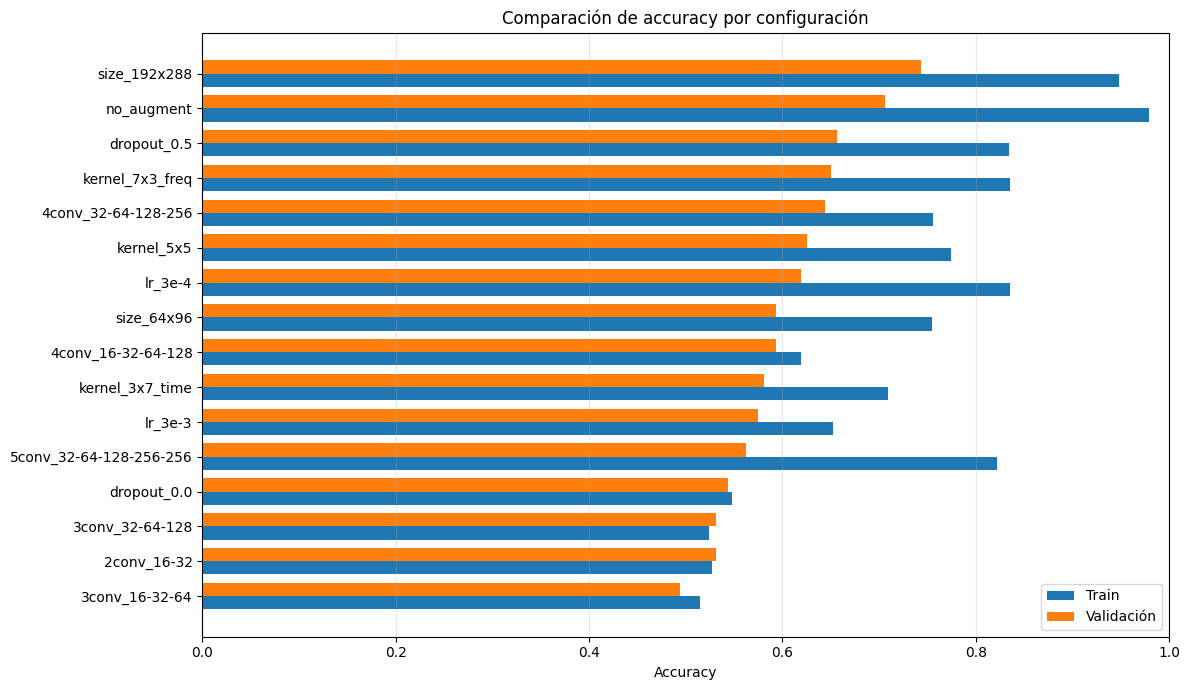

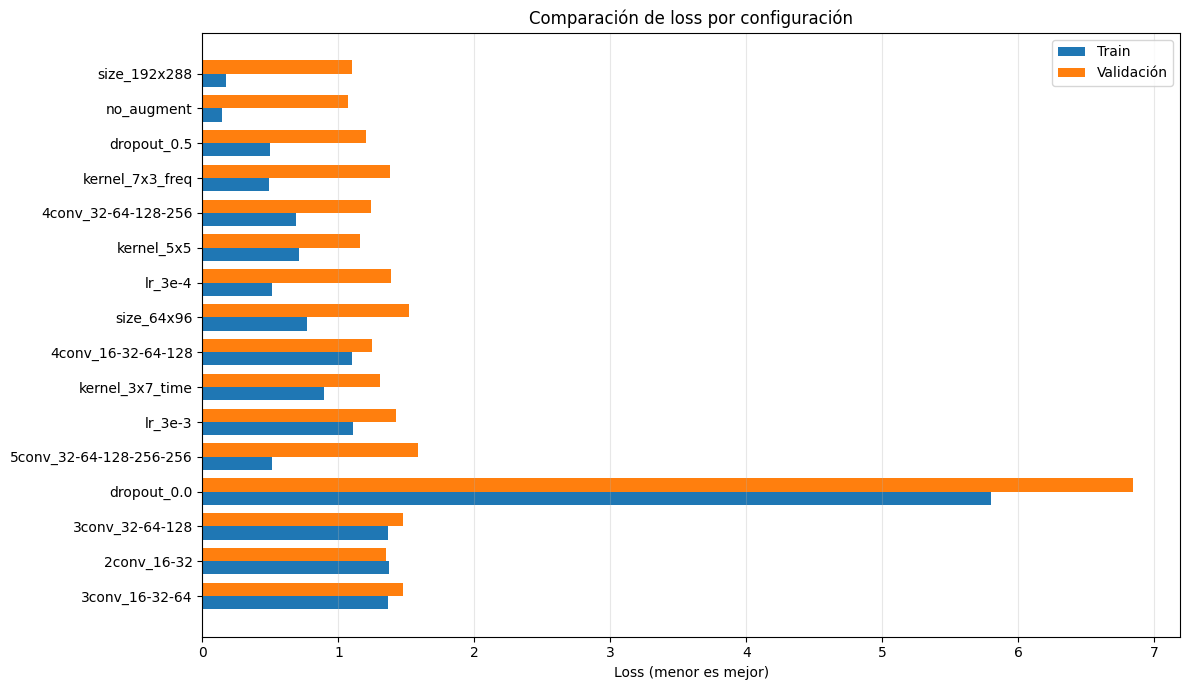

,Configuración,Accuracy train,Accuracy validación,Loss train,Loss validación,Mejor época,Épocas completadas,Filtros (Task 1),Bloques VGG16,Kernel,Dropout,Augmentation,Learning rate,Resolución
0,size_192x288,0.948357,0.74375,0.173689,1.097103,39,49,32 → 64 → 128 → 256,4,3×3,0.3,Sí,0.001,192×288


In [11]:
# Tabla comparativa con el rendimiento de todas las configuraciones.
results_rows = []
for name, run in experiment_results.items():
    config = run["config"]
    results_rows.append({
        "Configuración": name,
        "Accuracy train": run["train_accuracy"],
        "Accuracy validación": run["val_accuracy"],
        "Loss train": run["train_loss"],
        "Loss validación": run["val_loss"],
        "Mejor época": run["best_epoch"],
        "Épocas completadas": run["epochs"],
        "Filtros (Task 1)": " → ".join(map(str, config["filters"])),
        "Bloques VGG16": config["vgg_blocks"],
        "Kernel": f'{config["kernel"][0]}×{config["kernel"][1]}',
        "Dropout": config["dropout"],
        "Augmentation": "Sí" if config["augment"] else "No",
        "Learning rate": config["lr"],
        "Resolución": f'{config["size"][0]}×{config["size"][1]}',
    })

results_df = pd.DataFrame(results_rows)
results_df = results_df.sort_values(
    "Accuracy validación", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Gráfica comparativa de accuracy de entrenamiento y validación.
plot_df = results_df.sort_values("Accuracy validación", ascending=True)
fig, ax = plt.subplots(figsize=(12, 7))
positions = np.arange(len(plot_df))
height = 0.38
ax.barh(positions - height / 2, plot_df["Accuracy train"], height, label="Train")
ax.barh(positions + height / 2, plot_df["Accuracy validación"], height, label="Validación")
ax.set_yticks(positions)
ax.set_yticklabels(plot_df["Configuración"])
ax.set_xlabel("Accuracy")
ax.set_title("Comparación de accuracy por configuración")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Gráfica comparativa de loss en entrenamiento y validación.
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(positions - height / 2, plot_df["Loss train"], height, label="Train")
ax.barh(positions + height / 2, plot_df["Loss validación"], height, label="Validación")
ax.set_yticks(positions)
ax.set_yticklabels(plot_df["Configuración"])
ax.set_xlabel("Loss (menor es mejor)")
ax.set_title("Comparación de loss por configuración")
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Tabla con la configuración seleccionada según validación.
display(results_df.loc[[0], ["Configuración", "Accuracy train", "Accuracy validación",
                             "Loss train", "Loss validación", "Mejor época",
                             "Épocas completadas", "Filtros (Task 1)", "Bloques VGG16", "Kernel", "Dropout",
                             "Augmentation", "Learning rate", "Resolución"]])


## 8. Evaluación final en test

Se reconstruye la configuración ganadora y se cargan sus mejores pesos. Solo ahora se evalúa el conjunto de test, que no se ha usado para escoger hiperparámetros.

No cambies la configuración en función de estas métricas; si se usa test para tomar decisiones, deja de ser una evaluación independiente.

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 1 variables whereas the saved optimizer has 13 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,Modelo seleccionado,Loss en test,Accuracy en test,Imágenes de test
0,size_192x288,1.1193,0.705,200


,precision,recall,f1-score,support
Clase / métrica,,,,
blues,0.8000,0.400,0.5333,20.000
classical,0.9412,0.800,0.8649,20.000
country,0.6111,0.550,0.5789,20.000
disco,0.7222,0.650,0.6842,20.000
hiphop,0.7037,0.950,0.8085,20.000
jazz,0.6923,0.900,0.7826,20.000
metal,0.8824,0.750,0.8108,20.000
pop,0.6957,0.800,0.7442,20.000
reggae,0.6667,0.700,0.6829,20.000


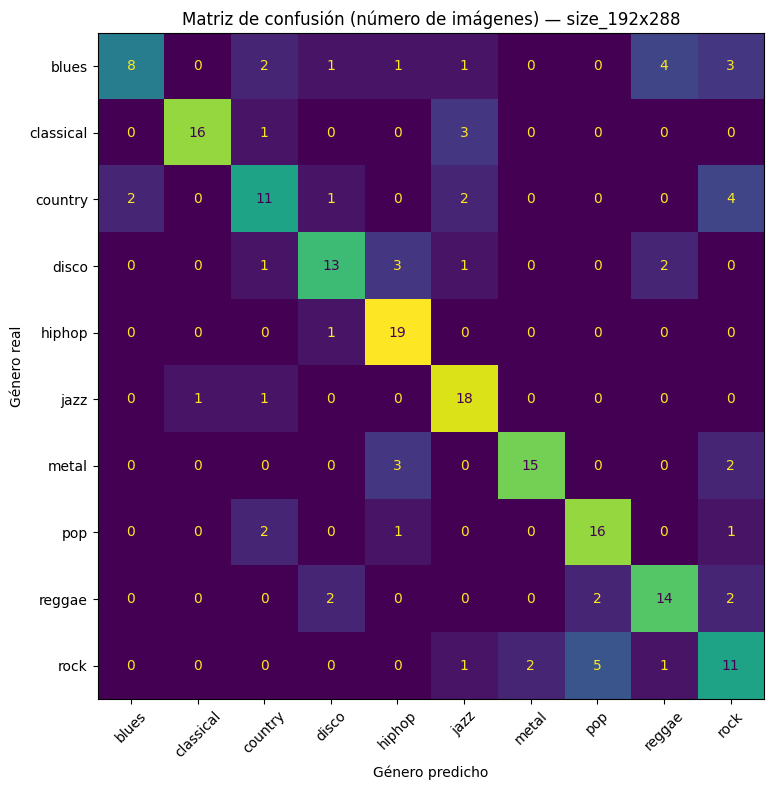

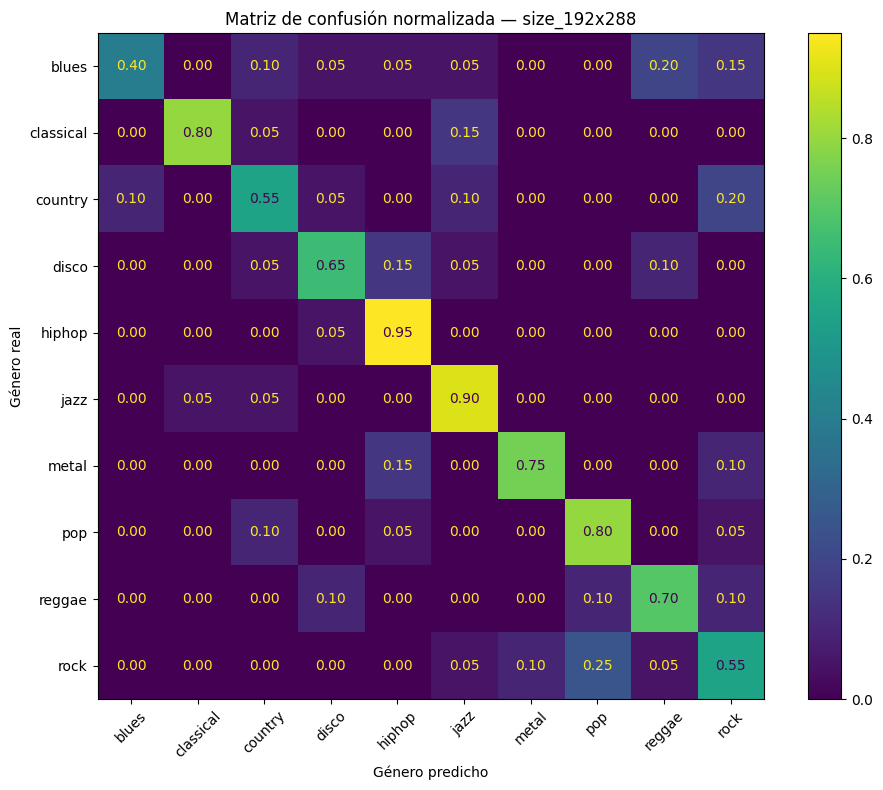

In [12]:
# Reconstruir la configuración ganadora y cargar sus mejores pesos.
tf.keras.backend.clear_session()
model = generate_model(num_classes, best_config)
model.load_weights(str(best_weights_file))

# El conjunto de test se usa solo para la evaluación final.
test_ds = make_dataset(
    test_paths, test_labels, best_config["size"], training=False
)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

# Tabla resumen de evaluación final.
display(pd.DataFrame([{
    "Modelo seleccionado": best_name,
    "Loss en test": test_loss,
    "Accuracy en test": test_accuracy,
    "Imágenes de test": len(test_labels),
}]).round(4))

# Predicciones e informe de clasificación como tabla.
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_labels

report = classification_report(
    y_true, y_pred,
    labels=range(num_classes),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)
report_df = pd.DataFrame(report).T
report_df.index.name = "Clase / métrica"
display(report_df.round(4))

# Matriz de confusión con recuentos absolutos.
cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, colorbar=False, values_format="d"
)
ax.set_title(f"Matriz de confusión (número de imágenes) — {best_name}")
ax.set_xlabel("Género predicho")
ax.set_ylabel("Género real")
plt.tight_layout()
plt.show()

# Matriz normalizada por género real: muestra la proporción de aciertos y errores.
cm_normalized = confusion_matrix(
    y_true, y_pred, labels=range(num_classes), normalize="true"
)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_normalized, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, colorbar=True, values_format=".2f"
)
ax.set_title(f"Matriz de confusión normalizada — {best_name}")
ax.set_xlabel("Género predicho")
ax.set_ylabel("Género real")
plt.tight_layout()
plt.show()


## 9. Curvas de aprendizaje

Las curvas muestran cómo cambia la accuracy y la loss durante cada época. Si la accuracy de entrenamiento sigue aumentando mientras la de validación se estanca o cae, puede haber sobreajuste. La selección final sigue basándose en la accuracy de validación, no en test.

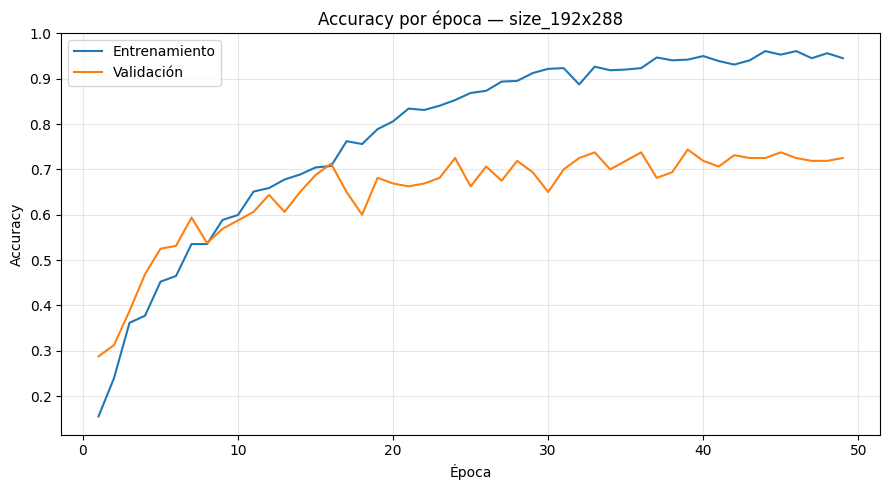

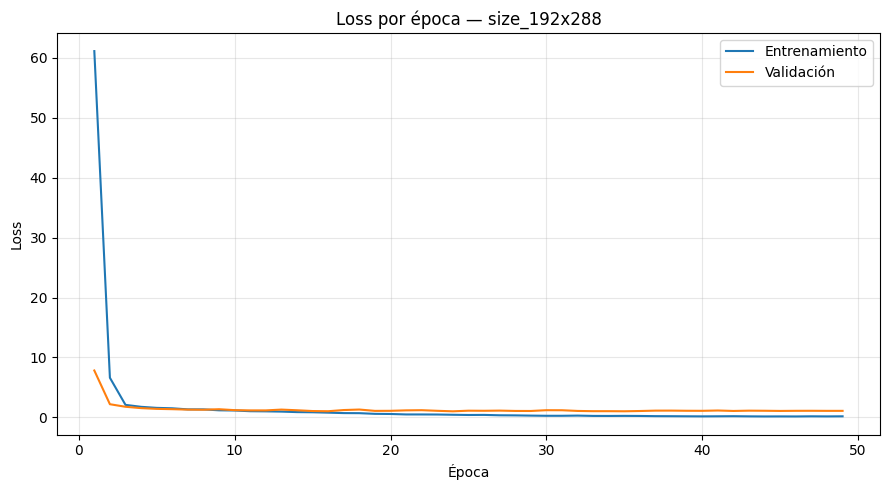

,Época,Accuracy train,Accuracy validación,Loss train,Loss validación
0,1,0.1549,0.2875,61.1473,7.8210
1,2,0.2394,0.3125,6.6089,2.1905
2,3,0.3615,0.3875,2.0832,1.7646
3,4,0.3772,0.4688,1.7562,1.5391
4,5,0.4523,0.5250,1.5813,1.4146
5,6,0.4648,0.5312,1.5095,1.3620
6,7,0.5352,0.5938,1.3311,1.2899
7,8,0.5352,0.5375,1.3269,1.2709
8,9,0.5884,0.5688,1.1747,1.3552
9,10,0.5994,0.5875,1.1418,1.2008


In [13]:
# Curvas de aprendizaje del mejor modelo: accuracy.
selected_history = experiment_results[best_name]["history"]
epochs_range = range(1, len(selected_history["accuracy"]) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs_range, selected_history["accuracy"], label="Entrenamiento")
ax.plot(epochs_range, selected_history["val_accuracy"], label="Validación")
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy")
ax.set_title(f"Accuracy por época — {best_name}")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Curvas de aprendizaje del mejor modelo: loss.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs_range, selected_history["loss"], label="Entrenamiento")
ax.plot(epochs_range, selected_history["val_loss"], label="Validación")
ax.set_xlabel("Época")
ax.set_ylabel("Loss")
ax.set_title(f"Loss por época — {best_name}")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Tabla por época para consultar los valores exactos del modelo ganador.
history_df = pd.DataFrame({
    "Época": list(epochs_range),
    "Accuracy train": selected_history["accuracy"],
    "Accuracy validación": selected_history["val_accuracy"],
    "Loss train": selected_history["loss"],
    "Loss validación": selected_history["val_loss"],
})
display(history_df.round(4))


## Resumen y cómo ejecutar

1. Abre el notebook en Google Colab desde el botón superior y monta Google Drive.
2. Comprueba que `DATA_DIR` apunte a `Data/images_original`.
3. Ejecuta las celdas en orden. Se recomienda activar una GPU desde **Entorno de ejecución → Cambiar tipo de entorno de ejecución**.
4. La búsqueda entrena 6 arquitecturas y 10 variaciones de hiperparámetros. Cada entrenamiento tiene un máximo de 50 épocas, con parada temprana.
5. Los resultados de esta versión se guardan en `MyDrive/MLSM/Lab 2/task1_results_v3/`. Si Colab se desconecta, vuelve a ejecutar las celdas: los experimentos ya guardados se omiten.
6. El modelo ganador se elige por validación y el conjunto de test se utiliza solo una vez para la evaluación final.

Los cambios de hiperparámetros afectan al entrenamiento de forma distinta: la profundidad y los filtros cambian la capacidad del modelo; dropout y AdamW regularizan; augmentation crea variaciones de entrenamiento; el learning rate afecta a la estabilidad y velocidad de aprendizaje; kernel y resolución cambian los patrones que puede detectar y el coste computacional.